# Neural Network Foundations

You have called `MLPClassifier().fit()` and it worked. This notebook starts from there. Part A trains an
`MLPClassifier` to recognize three penguin species and asks what the model is good for, and where it
stops. Part B writes the same network by hand in PyTorch, so that you can see every step that `.fit()`
hides, and change the things it does not let you change.

The examples are deliberately small enough to inspect rather than merely run.

## How to use this notebook

**What you should already know.** Basic Python (functions, loops, NumPy arrays, a pandas DataFrame), and
you have seen a small neural network being trained once, for example an `MLPClassifier` that you called
with `.fit()` and that simply worked.

**The first lesson.** This is the first lesson of the course. Notebook `00`, the homework before it, sets
up your environment. If your environment does not work yet, you can still follow: the examples are small
enough to read, and environment problems are solved at the end of the lesson or at the start of the next
one.

**The data.** The Palmer penguins: 342 penguins from three species (Adelie, Chinstrap, Gentoo), each
with four measurements. It is downloaded once through `seaborn` and kept in `../data/raw/penguins.csv`.

**How to work through it.** Run every cell in order, from top to bottom. Later cells use variables that
earlier cells create. Change the numbers in the code and run a cell again: that is the fastest way to see
what a setting does.

**Time.** About 1.5 hours, including the exercises.

**Goal.** After this notebook you can train an `MLPClassifier` properly, write the same network in
PyTorch, and say what each line of the training loop does.

**What you do _not_ need to master yet:**

- what happens mathematically inside `loss.backward()` (notebook `07` looks inside);
- the full PyTorch toolkit: `Dataset`, `nn.Module`, saving and loading (notebook `02` teaches that);
- tuning a network for the best possible score (notebooks `07`, `08` and `10` are about that).

## Learning objectives

After this notebook, you can:

- train an `MLPClassifier` on scaled features, and say why the scaler is fitted on the training data only;
- say what `MLPClassifier` is good for, and name three things it cannot do;
- match every argument of `MLPClassifier` to the line of PyTorch that replaces it;
- write the same network in PyTorch and explain what each of the five lines of the training loop does;
- say why there is a ReLU between the layers, and which activation belongs on the output;
- recognize overfitting in a table of train and test scores, and say where in the course the remedies
  are treated;
- say when a smaller model is the one to report.

# Part A: `MLPClassifier`, the thing you already know

## 1. Setup

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, log_loss, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.preprocessing import StandardScaler

# Training stops after max_iter passes over the data. If it has not converged by then, scikit-learn
# prints a ConvergenceWarning. We hide it here to keep the output readable, but in your own work it is
# a useful signal: it usually means "train longer, or lower the learning rate".
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# Neural networks start from random weights, so two runs give slightly different results. Fixing the
# seed makes every run in this notebook reproducible: you and your neighbour see the same numbers.
np.random.seed(42)

FEATURES = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
SPECIES = ["Adelie", "Chinstrap", "Gentoo"]


def load_penguins():
    '''Load the Palmer penguins: from the local copy if it exists, otherwise download it once.'''
    local_copy = Path("../data/raw/penguins.csv")
    if local_copy.exists():
        penguins = pd.read_csv(local_copy)
    else:
        penguins = sns.load_dataset("penguins")
        local_copy.parent.mkdir(parents=True, exist_ok=True)
        penguins.to_csv(local_copy, index=False)
    # Two penguins have no measurements at all. Dropping them is the only cleaning this notebook does.
    return penguins.dropna(subset=FEATURES).reset_index(drop=True)

## 2. The example: three species, one model

The Palmer penguins were measured on three islands near the Palmer research station in Antarctica. For
every penguin we have the species and four numbers: the length and depth of the bill, the flipper
length, and the body mass. The task: predict the species from the four measurements.

Look at the data before you model it. This is a habit worth keeping for the rest of the course.

In [2]:
penguins = load_penguins()
print(penguins.shape[0], "penguins")
print(penguins["species"].value_counts().to_string())
penguins.head()

342 penguins
species
Adelie       151
Gentoo       123
Chinstrap     68


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
4,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male


Three species, and not equally many of each: Chinstrap is less than half the size of Adelie. Keep that in
mind when you read an accuracy later; notebook `06` is about what imbalance does to a model.

Now the model you already know. Two things are standard and both matter:

- the data is split **before** anything is fitted, and `stratify=y` keeps the three species in the same
  proportions in train and test;
- the `StandardScaler` is fitted on the **training data only**, and then applied to both sets. The test
  set never influences any number the model learns, and stays untouched until the final evaluation.

In [3]:
X = penguins[FEATURES].to_numpy()
y = penguins["species"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
print(f"{len(X_train)} training penguins, {len(X_test)} test penguins")

# Scaling: learn the mean and standard deviation of each column from the training data only,
# then apply those same numbers to both sets.
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

network = MLPClassifier(
    hidden_layer_sizes=(16, 8),
    activation="relu",
    solver="adam",
    max_iter=2000,
    random_state=42,
)
network.fit(X_train_scaled, y_train)


def score_table(models):
    rows = {}
    for name, model in models.items():
        rows[name] = {
            "train accuracy": accuracy_score(y_train, model.predict(X_train_scaled)),
            "test accuracy": accuracy_score(y_test, model.predict(X_test_scaled)),
            "train log loss": log_loss(y_train, model.predict_proba(X_train_scaled)),
            "test log loss": log_loss(y_test, model.predict_proba(X_test_scaled)),
        }
    return pd.DataFrame(rows).T.round(3)


score_table({"MLPClassifier (16, 8)": network})

239 training penguins, 103 test penguins


,train accuracy,test accuracy,train log loss,test log loss
"MLPClassifier (16, 8)",0.996,0.99,0.023,0.024


The network gets about 99% of the test penguins right. The **log loss** is the second number to read:
accuracy only asks whether the top choice was right, log loss also asks how confident the model was, and
it punishes a confident mistake hard. A low log loss next to a high accuracy means the model is right
*and* sure. Notebook `05` is about reading such numbers properly.

Hold on to one question while you read on: is that score good because of the network, or because
penguins are easy? Section 6 comes back to it. **A network is not automatically the right
tool**, and this notebook ends by making you say when it is.

What did `.fit()` produce? A set of weights, one matrix and one bias vector per layer, and a record of
the loss after every pass over the data. Both are worth a look, because part B builds exactly these.

layer 1: weights (4, 16), biases (16,) -> 80 parameters
layer 2: weights (16, 8), biases (8,) -> 136 parameters
layer 3: weights (8, 3), biases (3,) -> 27 parameters

total trainable parameters: 243
epochs run: 383


with hidden_layer_sizes=(4,): 35 parameters, test accuracy 0.990


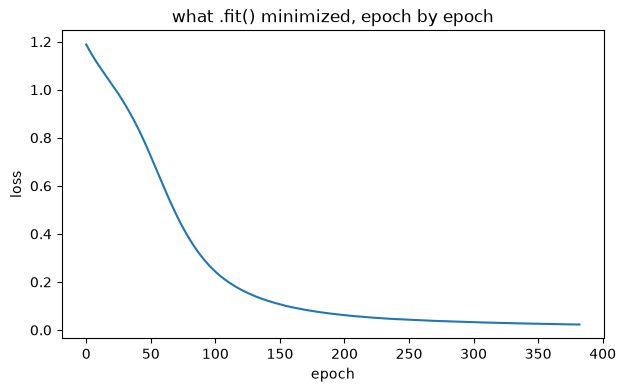

In [4]:
for layer, (layer_weights, layer_biases) in enumerate(zip(network.coefs_, network.intercepts_), start=1):
    print(f"layer {layer}: weights {layer_weights.shape}, biases {layer_biases.shape}"
          f" -> {layer_weights.size + layer_biases.size} parameters")
total_parameters = sum(w.size + b.size for w, b in zip(network.coefs_, network.intercepts_))
print(f"\ntotal trainable parameters: {total_parameters}")
print(f"epochs run: {network.n_iter_}")

# The same recipe with four hidden units, for comparison.
small_network = MLPClassifier(hidden_layer_sizes=(4,), max_iter=2000, random_state=42).fit(X_train_scaled, y_train)
small_parameters = sum(w.size + b.size for w, b in zip(small_network.coefs_, small_network.intercepts_))
print(f"with hidden_layer_sizes=(4,): {small_parameters} parameters, "
      f"test accuracy {accuracy_score(y_test, small_network.predict(X_test_scaled)):.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(network.loss_curve_)
ax.set(xlabel="epoch", ylabel="loss", title="what .fit() minimized, epoch by epoch")
plt.show()

Three layers: 4 measurements to 16 hidden units, 16 to 8, 8 to 3 species. Each layer has one weight per
connection plus one bias per unit, so `4 * 16 + 16 = 80`, `16 * 8 + 8 = 136` and `8 * 3 + 3 = 27`,
together 243 numbers that `.fit()` chose. The curve shows how: starting from random weights, it adjusted
them a little at a time, 383 passes over the training data, until the loss stopped improving. Part B
does the same thing in code you can read.

The last printed line is worth a pause: four hidden units, 35 parameters, and the same 0.99. Capacity only
helps when the data needs it, and section 6 comes back to that.

## 3. Why `MLPClassifier` is handy, and where it stops

**Handy.** You just trained a neural network in a handful of lines. The defaults are sensible: ReLU in
the hidden layers, softmax on the output, Adam as the optimizer, a reasonable learning rate.
`early_stopping=True` is one argument. The one thing it leaves to you is the scaling, and skipping it
is fatal: on the raw measurements the same network scores about 0.20, worse than always guessing Adelie,
because one learning rate cannot serve weights for grams and weights for millimetres at once. For a tabular dataset of a few hundred to a few hundred thousand rows,
this is the baseline to try first, and often the model you keep.

**Where it stops.** `MLPClassifier` is a fixed recipe: dense layers, one activation for all hidden
layers, cross-entropy as the loss, no GPU. You cannot add a convolution for images, put dropout between
two layers, write your own loss for an unusual task, or see what happens inside one training step. For
everything from notebook `02` onwards, where the inputs are images and the architecture matters, you
need a framework that lets you write the network yourself. That is part B.

**Key terms.** *Scaling*: putting every feature on the same scale (mean 0, standard deviation 1), with
numbers learned from the training data only. *Stratify*: split so that each class keeps the same
proportion in train and test. *Baseline*: the simplest model you take seriously, which every later model
has to beat. *Parameter*: a weight or a bias, a number the network learns. *Hyperparameter*: a setting
you choose yourself, such as `hidden_layer_sizes`.

# Part B: the same network, written by hand in PyTorch

## 4. From `.fit()` to a training loop

`MLPClassifier` hides everything inside `.fit()`. PyTorch makes every step visible. That costs about
fifteen lines of code instead of four, and it buys you the freedom to change anything: the layers, the
loss, what happens between two steps. From notebook `02` onwards, that freedom is not optional.

Same data, same split, same scaling as section 2, so the comparison is fair. Everything in the left
column of this table has a counterpart on the right.

| In `MLPClassifier` | In PyTorch |
|---|---|
| `hidden_layer_sizes=(16, 8)` | `nn.Linear(4, 16)`, `nn.Linear(16, 8)`, `nn.Linear(8, 3)` |
| `activation="relu"` | `nn.ReLU()` between the layers |
| the loss, chosen for you: cross-entropy | `nn.CrossEntropyLoss()` |
| `solver="adam"` | `torch.optim.Adam(...)` |
| `learning_rate_init=0.001` | `lr=0.01` |
| `batch_size=200` (the default, capped at the data size) | `DataLoader(..., batch_size=32)` |
| `max_iter` | `for epoch in range(200)` |
| one training step, hidden inside `.fit()` | `zero_grad()`, forward, loss, `backward()`, `step()` |
| `X_train_scaled`, by hand | the same arrays, turned into tensors |
| `classes_` | you map the species to `0, 1, 2` yourself |

Two things to notice in that table. The PyTorch network ends in three raw scores and **no softmax**:
`nn.CrossEntropyLoss` turns the scores into probabilities itself. Adding your own softmax before it is a
common and quietly damaging mistake. And the learning rate is a different number because the batches are
different: more, smaller batches per epoch means more updates, and notebook `07` works out how those two
interact.

### Step 1: data as tensors

PyTorch does not work on NumPy arrays but on **tensors**: the same idea, a grid of numbers with a shape,
with two extras. A tensor can live on a GPU, and it can remember how it was computed, which is what makes
`loss.backward()` in step 3 possible. A table of 239 penguins by 4 measurements is a tensor with shape
`(239, 4)`; the 239 labels are a tensor with shape `(239,)`. Two details to get right from the start: the
measurements are `float32` (the type PyTorch models are built in) and the labels are `int64`
(`torch.long`), because `CrossEntropyLoss` wants class *indices*, not names. Notebook `02`, section 1,
is the full story.

Training does not use all 239 penguins at once. The `DataLoader` hands them out in shuffled **batches**
of 32, and one pass over all the batches is an **epoch**. `MLPClassifier` did the same thing; it just
never showed you.

In [5]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)

# The same scaled arrays as section 2, now as tensors.
species_to_index = {species: index for index, species in enumerate(SPECIES)}

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor([species_to_index[s] for s in y_train], dtype=torch.long)
y_test_tensor = torch.tensor([species_to_index[s] for s in y_test], dtype=torch.long)

train_loader = DataLoader(TensorDataset(X_train_tensor, y_train_tensor), batch_size=32, shuffle=True)

print("features:", X_train_tensor.shape, X_train_tensor.dtype)
print("labels  :", y_train_tensor.shape, y_train_tensor.dtype, "  first five:", y_train_tensor[:5].tolist())
print("batches per epoch:", len(train_loader))

features: torch.Size([239, 4]) torch.float32
labels  : torch.Size([239]) torch.int64   first five: [0, 0, 2, 0, 0]
batches per epoch: 8


### Step 2: the network, the loss and the optimizer

Read `nn.Sequential` from top to bottom: 4 measurements go to 16 hidden units, ReLU, 16 to 8, ReLU, and
8 to 3 raw scores. That is `hidden_layer_sizes=(16, 8)`, written out one line per layer. Each
`nn.Linear` is a weight matrix and a bias vector, exactly like `network.coefs_` and
`network.intercepts_` in section 2; `nn.ReLU` is the activation that lets the network bend.

Then two more objects. The **loss** is one number that says how wrong a batch of predictions was;
cross-entropy is the usual choice for classification and the one `MLPClassifier` uses too. The
**optimizer** is the rule that turns "how wrong" into "change the weights this way". It is handed the
parameters it is allowed to change, and a **learning rate** that sets how big each change is.

In [6]:
pytorch_network = nn.Sequential(
    nn.Linear(4, 16),
    nn.ReLU(),
    nn.Linear(16, 8),
    nn.ReLU(),
    nn.Linear(8, 3),
)
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(pytorch_network.parameters(), lr=1e-2)

print(pytorch_network)
sklearn_parameters = sum(w.size + b.size for w, b in zip(network.coefs_, network.intercepts_))
print("\ntrainable parameters:", sum(parameter.numel() for parameter in pytorch_network.parameters()),
      f"  (MLPClassifier had {sklearn_parameters})")

Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=3, bias=True)
)

trainable parameters: 243   (MLPClassifier had 243)


### Why the ReLU in between

Every `nn.Linear` layer does the same thing: multiply the inputs by weights and add a bias. That is a
weighted sum, and a weighted sum of weighted sums is just another weighted sum. So two `nn.Linear` layers
in a row, with nothing between them, can do no more than one layer: they can only draw straight lines
through the data, however many you stack.

The **activation function** is the small, non-linear function placed after each layer that breaks this.
With a bend after every layer, the network can bend its decision too. That is the whole reason it is
there, and it is why `hidden_layer_sizes=(16, 8)` in `MLPClassifier` comes with `activation="relu"`.

The three functions you will see, and the one on the output:

| Function | What it does with the weighted sum $z$ | Where it is used |
|---|---|---|
| **ReLU** | keeps $z$ if it is positive, outputs 0 otherwise | between the layers; the default in this course |
| **Sigmoid** | squeezes $z$ into a number between 0 and 1 | on the output, for a yes-or-no answer (a probability) |
| **Tanh** | squeezes $z$ into a number between -1 and 1 | between the layers in older networks |
| **Softmax** | turns a row of scores into probabilities that add up to 1 | on the output, for several classes; in this notebook it sits inside `CrossEntropyLoss` |

Why ReLU between the layers, and not sigmoid or tanh? Look at the curves below. Sigmoid and tanh go flat
for large positive or negative $z$: once a unit is in the flat part, changing its weights barely changes
its output, so the network learns slowly there. ReLU is a straight line for every positive $z$, so it
never flattens on that side. It is also the cheapest of the three to compute. One ReLU unit *can* get
stuck at zero for every input (a "dead" unit), which is the price; in practice a layer has enough units
that it rarely matters.

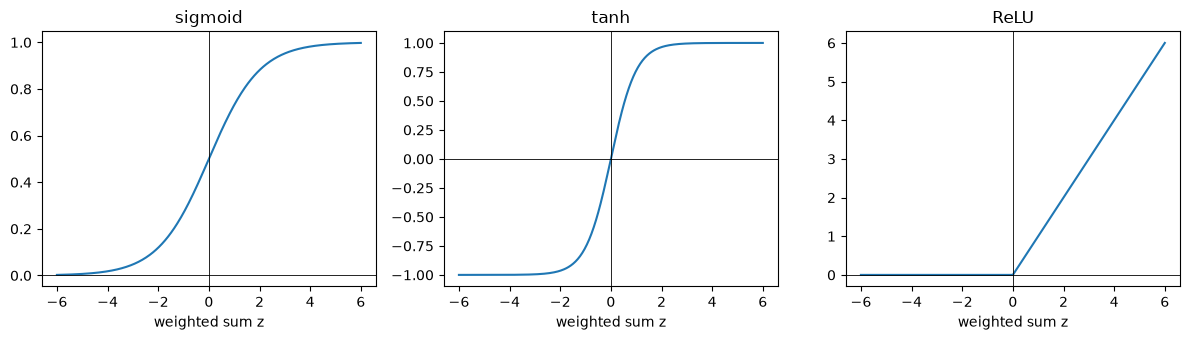

In [7]:
z = torch.linspace(-6, 6, 400)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, values, name in zip(axes, [torch.sigmoid(z), torch.tanh(z), torch.relu(z)], ["sigmoid", "tanh", "ReLU"]):
    ax.plot(z, values)
    ax.axhline(0, color="black", linewidth=0.6)
    ax.axvline(0, color="black", linewidth=0.6)
    ax.set_title(name)
    ax.set_xlabel("weighted sum z")
plt.tight_layout()
plt.show()

Read the three panels as "what comes out for a given weighted sum". Sigmoid and tanh are S-shaped and
flat at both ends; ReLU is flat only on the left and a straight line on the right. For the output layer
the choice follows from the question (one probability, or several that sum to 1); for the layers in
between, use ReLU unless you have a reason not to.

**Key terms.** *Activation function*: the non-linear function after a layer. *ReLU*: zero for negative
input, unchanged for positive input. *Sigmoid*: squeezes to 0 to 1. *Softmax*: several scores to
probabilities that sum to 1. *Dead unit*: a ReLU unit that outputs zero for all inputs.

### Step 3: the training loop

Five lines, and they are the same in every PyTorch project you will ever read:

1. `optimizer.zero_grad()` forgets the gradients of the previous step. PyTorch *adds* new gradients to
   old ones by default, so without this line every step would use the sum of all gradients so far.
2. The forward pass: the network makes its prediction for one batch.
3. The loss says how wrong that prediction was.
4. `loss.backward()` computes the **gradient**: for every one of the 243 parameters, how much the loss
   would change if that parameter were nudged a little. That is the information the optimizer needs.
5. `optimizer.step()` moves every parameter a little in the direction that lowers the loss, by an amount
   set by the learning rate.

Repeat for every batch, and then for two hundred epochs. That is all `.fit()` does.

Around the loop, two lines you have not seen. `train()` and `eval()` switch the network between training
and evaluation behaviour (nothing changes for this network, but dropout in exercise 1 will care), and
`torch.no_grad()` tells PyTorch not to record operations while evaluating, which saves memory and time.
Notebook `02` explains both properly.

PyTorch train accuracy: 1.000
PyTorch test accuracy : 0.990


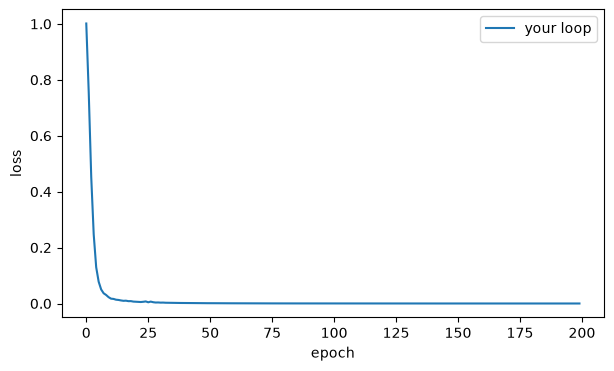

In [8]:
epoch_losses = []
for epoch in range(200):
    pytorch_network.train()
    running_loss = 0.0
    for batch_features, batch_labels in train_loader:
        optimizer.zero_grad()                              # 1. forget the previous gradients
        logits = pytorch_network(batch_features)           # 2. forward pass: raw scores for 3 species
        loss = loss_function(logits, batch_labels)         # 3. how wrong are we?
        loss.backward()                                    # 4. gradient: how to change every weight
        optimizer.step()                                   # 5. change every weight a little
        running_loss += loss.item() * len(batch_labels)
    epoch_losses.append(running_loss / len(train_loader.dataset))

pytorch_network.eval()
with torch.no_grad():
    train_predictions = pytorch_network(X_train_tensor).argmax(dim=1)
    test_predictions = pytorch_network(X_test_tensor).argmax(dim=1)

print(f"PyTorch train accuracy: {(train_predictions == y_train_tensor).float().mean().item():.3f}")
print(f"PyTorch test accuracy : {(test_predictions == y_test_tensor).float().mean().item():.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epoch_losses, label="your loop")
ax.set(xlabel="epoch", ylabel="loss")
ax.legend()
plt.show()

### Exercise 1: change it in both, then change it in one

**A. Look and read off** (2 minutes). Compare the PyTorch accuracies with the table in section 2. Same
data, same architecture, same loss: why are the numbers not exactly equal?

**B. In both** (10 minutes). Add a third hidden layer of 8 units. In scikit-learn that is one more
number in the tuple; in PyTorch it is two more lines in `nn.Sequential`. Train both and compare their
test accuracy and their parameter count.

**C. Only in PyTorch** (15 minutes). Pick one:

1. Record the loss per *batch* instead of per epoch (append `loss.item()` inside the inner loop) and plot
   it. Why is it so much noisier than the epoch curve, and what does that say about what one batch
   tells you?
2. Put `nn.Dropout(0.3)` between the two hidden layers, train again, and compare train and test
   accuracy. Then evaluate once *without* calling `pytorch_network.eval()` first. What changes, and why?

Neither of these is possible with `MLPClassifier`. This is what the extra lines buy.

In [9]:
# B. Your turn: a third hidden layer, in both libraries.
# deeper_sklearn = MLPClassifier(hidden_layer_sizes=(16, 8, 8), max_iter=2000, random_state=42).fit(X_train_scaled, y_train)
# deeper_pytorch = nn.Sequential(nn.Linear(4, 16), nn.ReLU(), nn.Linear(16, 8), nn.ReLU(), nn.Linear(8, 8), nn.ReLU(), nn.Linear(8, 3))

# C. Your turn: per-batch losses, or dropout.

<details>
<summary>Worked answer: Exercise 1</summary>

**A.** Both start from random weights, but from *different* random weights (two libraries, two random
number generators), and they take different paths: scikit-learn used batches of 200 at a learning rate
of 0.001, this loop used batches of 32 at 0.01, so the number and size of the updates differ. Two runs
of the same recipe land in slightly different places, and on 103 test penguins one penguin is a full
percentage point. Which is why a difference of one penguin is not a finding (section 6).

**B.** `hidden_layer_sizes=(16, 8, 8)` and `nn.Linear(8, 8), nn.ReLU()` inserted before the last layer.
Both add `8 * 8 + 8 = 72` parameters, for 315 in total. Test accuracy stays around 0.99: a third layer
has nothing to add on this data.

**C.**

1. The per-batch curve is a saw-tooth around the epoch curve. Each batch is 32 penguins, so its loss is
   a noisy estimate of the loss over all 239, and a batch that happens to contain hard penguins scores
   worse than the one before. The epoch curve is the average of eight such batches, which smooths it.
   One batch tells you the direction of the gradient roughly, not the state of the model. Notebook `07`
   is about reading these curves.
2. With dropout, training accuracy drops slightly (the network is trained with 30% of the hidden units
   randomly switched off at every step) and test accuracy stays about the same: there is little
   overfitting to prevent here. Evaluating without `eval()` leaves dropout *on*, so the predictions are
   made by a randomly crippled network and change from one call to the next. `eval()` switches it off.
   Notebook `02` has a table of what `train()` and `eval()` change, and notebook `08` explains why
   dropout regularizes.

</details>

## 5. Overfitting, in one table

Overfitting occurs when a model learns training-specific noise or detail that does not generalize.
Typical evidence is a training score that keeps improving while the validation score stalls or worsens.

To see it, you need a model with far more capacity than the data supports. The full penguin set is too
well behaved for that, so take a small, hard slice of it: thirty penguins, the two bill measurements only,
and a network of two hundred hidden units with almost no regularization. Next to it, the same network
with a strong L2 penalty (`alpha`), which punishes large weights and so keeps the model from bending its
decision around individual penguins.

In [10]:
bill_columns = [FEATURES.index(f) for f in ["bill_length_mm", "bill_depth_mm"]]
X_small_train, X_small_test, y_small_train, y_small_test = train_test_split(
    X[:, bill_columns], y, train_size=30, stratify=y, random_state=7
)
# A new split needs its own scaler, fitted on these thirty penguins only.
small_scaler = StandardScaler().fit(X_small_train)
X_small_train = small_scaler.transform(X_small_train)
X_small_test = small_scaler.transform(X_small_test)


def fit_and_score(name, hidden_layers, alpha):
    candidate = MLPClassifier(hidden_layer_sizes=hidden_layers, alpha=alpha, max_iter=3000, random_state=7)
    candidate.fit(X_small_train, y_small_train)
    return {
        "model": name,
        "train_accuracy": accuracy_score(y_small_train, candidate.predict(X_small_train)),
        "test_accuracy": accuracy_score(y_small_test, candidate.predict(X_small_test)),
        "test_log_loss": log_loss(y_small_test, candidate.predict_proba(X_small_test), labels=SPECIES),
    }


comparison = [
    fit_and_score("high capacity, weak L2", (100, 100), 1e-8),
    fit_and_score("high capacity, strong L2", (100, 100), 1.0),
]
pd.DataFrame(comparison).set_index("model").round(3)

,train_accuracy,test_accuracy,test_log_loss
model,,,
"high capacity, weak L2",1.000,0.949,0.117
"high capacity, strong L2",0.967,0.962,0.147


The first model is perfect on its thirty training penguins and worse on the rest; the second gets a
training penguin wrong on purpose and is right more often on penguins it has never seen. The first has
bent its decision to rescue individual training penguins, and those bends do not transfer. **This is what
overfitting looks like in a table**: training score up, test score down, and it is the pair of numbers
to look for in your own projects. The gap is a few points here because even thirty penguins are fairly
clean data; on noisier data it is tens of points.

One number in the table goes the other way: the strongly regularized model has the *higher* test log
loss. The penalty keeps the weights small, and small weights mean cautious probabilities, so this model is
right more often but less sure of it. Which of the two you prefer depends on what the probabilities are
for; notebook `05` is about that.

Common controls, each with its own notebook:

- **Reduce capacity:** fewer layers or units (section 2: four hidden units did as well as sixteen plus eight).
- **L2 regularization (weight decay):** penalize large weights; `MLPClassifier` uses `alpha`. Notebook `08`.
- **Early stopping:** stop on validation performance rather than training loss. Notebook `07`.
- **Dropout:** randomly deactivate units during training (exercise 1C). Notebook `08`.
- **More representative data:** often more valuable than architectural complexity. Notebook `04`.
- **Data augmentation:** create label-preserving variations when the domain allows it. Notebook `09`.

Regularization strength and architecture are hyperparameters. Choose them with validation data or
cross-validation, never by repeatedly checking the final test set; notebook `10` is about that.

**Key terms.** *Overfitting*: fitting noise in the training data that does not generalize.
*Generalization*: performance on data the model has never seen. *Capacity*: how complicated a decision a
model can make. *L2 regularization / weight decay*: a penalty on large weights (`alpha`). *Early
stopping*: stop training when validation performance stops improving.

### Exercise 2: one change, several seeds

**A. Look and read off** (2 minutes). Call `fit_and_score` once more with `hidden_layer_sizes=(16,)` and
`alpha=0.1`. Where does a *smaller* network land, compared with the two in the table?

**B. Do it yourself** (10 minutes). The two models in the table differ by about one penguin in ten on
the test set. Repeat both with `random_state=0, 1, 2` inside `MLPClassifier` (you will have to copy
`fit_and_score` and add a `seed` argument). Is the difference between the two models bigger than the
spread between seeds of the same model? One sentence on what that means; notebook `10` makes a method
of it.

In [11]:
# A. One extra configuration in the existing comparison.
pd.DataFrame(comparison + [fit_and_score("low capacity, moderate L2", (16,), 0.1)]).set_index("model").round(3)

# B. Your turn: the same two configurations with seeds 0, 1 and 2.

,train_accuracy,test_accuracy,test_log_loss
model,,,
"high capacity, weak L2",1.000,0.949,0.117
"high capacity, strong L2",0.967,0.962,0.147
"low capacity, moderate L2",0.967,0.939,0.158


<details>
<summary>Worked answer: Exercise 2</summary>

**A.** Lowest of the three, at about 0.94: a small network and a penalized large one are two routes to
a decision that cannot twist around single penguins, but they are not the same route, and here the
sixteen-unit network is slightly too rigid. "Smaller" is not automatically "safer". Notebook `08`
compares the routes properly.

**B.** On this split the ranking survives: with seeds 0, 1 and 2 the weak-L2 model scores 0.949 to 0.952,
the strong-L2 model 0.958 to 0.965, and the small one 0.936 to 0.942. The spread within a model is under
one point, the difference between the two large models is about one point, and that is three penguins out
of 312. So the difference is real on this split, and small. Had the spread been as large as the
difference, you would have shown nothing. Checking that before believing a comparison is the most
important habit in small experiments, and it is why notebooks `08` and `10` insist on repeating runs.

</details>

<details>
<summary>Note for the curious: the second split</summary>

The seed only changes the network's starting weights. The thirty training penguins are the same in
every run, because `train_test_split` has its own `random_state=7`. Changing *that* seed changes which
thirty penguins you train on, and on a set this small that matters more than the network's seed. Try it.

</details>

## 6. Responsible evaluation

A network can minimize its loss perfectly and still be the wrong thing to deploy. Four questions to ask
about the model you just trained, before any of the bigger ones:

1. **What does a mistake cost?** The model outputs three probabilities; `predict` picks the largest.
   For penguins that is harmless. For a medical or financial decision, the costs of the different
   mistakes differ, and "pick the largest" is an arbitrary rule. Notebook `05` is about choosing the
   rule.
2. **Is the training data like the data you will meet?** These penguins were measured on three islands
   in three seasons. A penguin from a fourth island is not covered by any number in this notebook.
3. **Does a simpler model do just as well?** In section 2 a network with four hidden units scored the same 0.99 as
   sixteen plus eight, with 35 parameters instead of 243.
   Here the honest answer is: the big network is not needed. Ten accuracy points would justify the extra
   complexity; zero does not.
4. **Is the result stable?** You saw single runs, with one seed and one split. A difference smaller than
   the variation between seeds is not a finding (exercise 2).

Model complexity should be justified by a reliable improvement on the real objective, not by novelty.

<details>
<summary>The longer checklist, for when you deploy something for real</summary>

- Does the training population represent the people affected?
- Are labels valid, or do they reproduce historical bias?
- Are predicted probabilities calibrated?
- Do error rates and harms differ across relevant groups?
- Is the chosen decision rule appropriate for the costs of the different mistakes?
- Could sensitive information be reconstructed through proxy variables?
- Is a less complex, more interpretable model competitive?
- How will drift, failures, appeals, and human oversight be monitored?

</details>

### Final exercise: fill in a model card

A model card is a short page that answers, for someone who did not build the model, "what is this,
and when should I not trust it?". Copy the template below into a markdown cell and fill it in for the
penguin network from section 2 or section 4. One or two lines per heading is enough; the example lines
show the level of detail.

```markdown
# Model card: <name>

## Intended use
For: ...                      e.g. identifying the species of an adult penguin from four measurements, for teaching
Not for: ...                  e.g. penguins from other regions, chicks, any other species

## Data
Source: ...                   e.g. Palmer Station Antarctica LTER, 2007 to 2009, via seaborn
Unit of observation: ...      e.g. one adult penguin
Known gaps: ...               e.g. three islands only; Chinstrap is under-represented (68 of 342)

## Model
Architecture: ...             e.g. MLP, hidden layers (16, 8), ReLU, softmax output, 243 parameters
Loss and optimizer: ...       e.g. cross-entropy, Adam, learning rate 0.001
Regularization: ...           e.g. alpha=0.0001 (default), no early stopping

## How it was selected
Split: ...                    e.g. 70/30 stratified, random_state=42
Choices based on: ...         e.g. defaults; test set used once, at the end

## Performance
Score: ...                    e.g. 0.99 test accuracy, 0.02 test log loss
Uncertainty: ...              e.g. not measured; one seed, one split
Simpler baseline: ...         e.g. hidden_layer_sizes=(4,), 35 parameters, also 0.99

## Limitations
Fails when: ...               e.g. measurements on a different scale than the training data; missing values
Monitoring: ...               e.g. none, this model is not deployed
```

## Typical mistakes

The errors that cost the most time when you start, and how to spot them.

| Mistake | What you see | What to do |
|---|---|---|
| Not scaling the features | the network learns badly or not at all (section 3) | fit a `StandardScaler` on the training data and `transform` both sets |
| Fitting the scaler on all data | test scores that look suspiciously good | `scaler.fit(X_train)` only; the test set gets `transform`, never `fit` |
| Judging by training loss | loss drops nicely, test results disappoint | always look at validation or test performance alongside it |
| Concluding from one run | two configurations "differ" by one penguin | repeat with several `random_state` values and compare the spread |
| Ignoring the convergence warning | a model that is simply not finished training | raise `max_iter`, or check that the loss curve has flattened |
| Forgetting `optimizer.zero_grad()` | the PyTorch loss rises erratically | it is the first line of the loop |
| A softmax before `CrossEntropyLoss` | the PyTorch model learns slowly or not at all | end the network with raw scores; the loss applies softmax itself |
| Labels as `float` or as names | a dtype error from `CrossEntropyLoss` | map the classes to `0, 1, 2` and use `torch.long` |
| Accuracy on imbalanced classes | 95% accuracy on a class that occurs 95% of the time | use a suitable metric (notebook `05`) and check class balance (notebook `06`) |
| More units as a first reflex | training accuracy rises, test accuracy falls | first check the data and the preprocessing; capacity is rarely the first problem |

## Glossary

| Term | In one line |
|---|---|
| Weight | a number saying how heavily one input counts |
| Bias | a number shifting how easily a unit activates |
| Parameter | a weight or a bias; something the network learns |
| Hyperparameter | a setting you choose yourself, such as layer sizes or `alpha` |
| Scaling | putting every feature on the same scale, with numbers learned from the training data only |
| Baseline | the simplest model you take seriously; every later model has to beat it |
| Hidden layer | a layer between input and output; `hidden_layer_sizes` or `nn.Linear` |
| Activation function | the nonlinear function after each layer (ReLU here) that lets the network bend |
| Softmax | turns the raw output scores into probabilities that sum to 1; `CrossEntropyLoss` applies it |
| Loss | one number for how wrong the predictions are |
| Cross-entropy / log loss | the usual loss for classification; two names, one thing |
| Gradient | per parameter: how much the loss changes if you nudge it; what `backward()` computes |
| Learning rate | how large a step the optimizer takes |
| Batch | the group of examples used for one update |
| Epoch | one full pass through the training data |
| Optimizer | the rule turning gradients into updates (SGD, Adam) |
| Tensor | PyTorch's array: like NumPy's, but it can live on a GPU and carry gradients |
| Training loop | `zero_grad()`, forward, loss, `backward()`, `step()`; the same in every project |
| Overfitting | fitting noise in the training data that does not generalize |
| Generalization | performance on data the model has never seen |
| Capacity | how complicated a decision a model can make |
| L2 / weight decay | a penalty on large weights (`alpha` in `MLPClassifier`) |
| Early stopping | stop training when validation performance stops improving |

## Knowledge check

Answer these before opening the suggested answers.

1. Why must the scaler be fitted on training data only?
2. Name three things `MLPClassifier` cannot do that PyTorch can.
3. Name the five lines of the PyTorch training loop, in order, and say what each one does.
4. What does `loss.backward()` compute, and what does `optimizer.step()` do with it?
5. Your PyTorch model ends with `nn.Softmax()` followed by `nn.CrossEntropyLoss()`. What is wrong?
6. Why can training loss fall while test performance worsens?
7. A network with four hidden units and one with sixteen plus eight both score 0.99 on the penguins.
   Which do you report, and why?
8. Two configurations differ by one test penguin. What do you do before calling one of them better?

<details>
<summary>Suggested answers</summary>

1. Fitting on all data leaks the mean and standard deviation of the test cases into training and
   produces an optimistic evaluation. Call `fit` on `X_train` only, and `transform` on both sets.
2. Convolutions for images, dropout between layers, a loss of your own, a GPU, and anything that
   happens between two training steps (logging, a custom schedule).
3. `optimizer.zero_grad()` forgets the previous gradients; the forward pass makes the prediction; the
   loss says how wrong it was; `loss.backward()` computes the gradient for every parameter;
   `optimizer.step()` changes every parameter a little.
4. For every parameter, how much the loss would change if that parameter were nudged. The optimizer
   moves each parameter a little in the direction that lowers the loss, by an amount set by the
   learning rate.
5. `CrossEntropyLoss` applies softmax itself, so the model now applies it twice. The second softmax
   squashes the already-small differences between probabilities, the gradients become tiny, and the
   model learns slowly or not at all. End the network with raw scores.
6. The network can increasingly fit training-specific noise that does not generalize.
7. The small one. Same score, 35 parameters instead of 243, and no evidence that the extra capacity buys
   anything (section 6, question 3). Report both numbers and say so.
8. Repeat both with several seeds. If the difference is smaller than the spread between seeds of one
   configuration, you have not shown a difference.

</details>

## Recap

- `MLPClassifier` on scaled features is a neural network in a few lines, and a baseline worth taking
  seriously; it hides the training loop inside `.fit()`.
- Fit the scaler on the training data only. Without scaling a network does not learn at all.
- Every argument of `MLPClassifier` has a line of PyTorch that replaces it, and the network has exactly
  the same 243 parameters in both.
- The PyTorch training loop is five lines and the same in every project; what changes is the network
  inside it.
- `backward()` computes how to change every weight, `step()` changes it; `zero_grad()` comes first.
- Generalization has to be measured separately from training fit, one run is not evidence, and a
  simpler model that scores the same is the one to report.